# PyG proof of concept: can graph structure detect local EdU clustering?

**Question:** Among simulated Dpn-like cells, can a graph neural network detect whether the EdU-positive cells form a local cluster instead of being randomly scattered?

This notebook uses **entirely synthetic data**, not animal observations, segmented `.lif` files, or real treatment labels. One graph is one synthetic lobe; each node is a Dpn-like cell. Its node features are EdU-positive status, log-volume, and a Dpn-intensity proxy. Edges connect nearby cell centroids. They encode proximity, not synapses or Vistiq's IoS containment relation.

Each *matched pair* has exactly the same centroids, spatial edges, volumes, intensity values, cell count, and number of EdU-positive cells. Only the **spatial assignment** of EdU positivity differs. A geometry/feature-summary baseline should therefore stay near chance; an explicit edge-homophily baseline provides a fairer comparison for the GNN.

Run in **Python (Vistiq POC)** on an OOD session with a CUDA GPU. Nothing is read from disk or written besides the notebook's own outputs. Even a successful result demonstrates a simulation method, **not a biological finding**.


In [1]:
import sys
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv, global_mean_pool, global_max_pool
from torch_geometric.utils import to_undirected
import torch_geometric

SEED = 17
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU unavailable. In OOD request Interactive GPU: Yes and restart this kernel.')
device = torch.device('cuda:0')
print('Python:', sys.executable)
print('PyTorch:', torch.__version__, 'PyG:', torch_geometric.__version__)
print('GPU:', torch.cuda.get_device_name(device))


Python: /sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/bin/python
PyTorch: 2.5.0+cu124 PyG: 2.8.0.post1
GPU: Tesla V100-SXM2-32GB


## 1. Generate matched lobes

Draw between 55 and 95 cell centroids in a normalized 3D lobe. Cell volume and Dpn intensity are noisy measurements drawn independently of the class. For each geometry, produce **two** examples:

- **0, scattered:** choose approximately 30% of the cells uniformly at random to be EdU-positive.
- **1, partially clustered:** choose some of the EdU-positive cells near a random anchor cell; choose the remaining positive cells at random. The clustering fraction varies across simulated lobes (35–65%).

Both partners have the **same number** of EdU-positive cells. The class label says which *generating process* was used, not an observed animal outcome. These classes deliberately overlap because some random arrangements also produce local clusters. Coordinates and other cell properties are reused exactly within each pair, so radial location, cell density, and mean marker signal cannot separate paired labels.


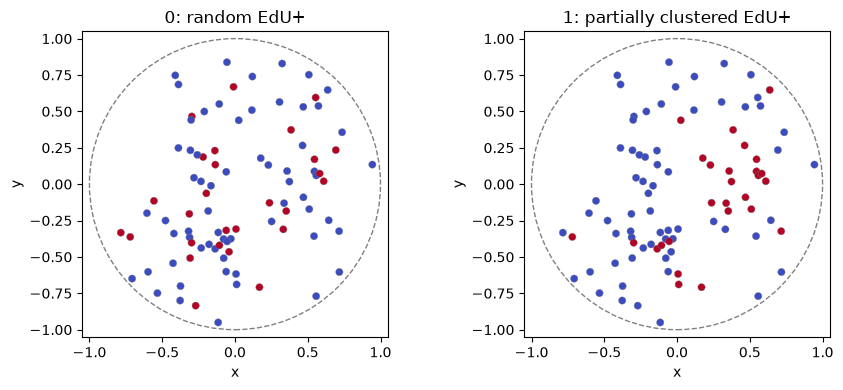

In [2]:
def simulate_pair(rng: np.random.Generator):
    n = int(rng.integers(55, 96))
    theta = rng.uniform(0, 2 * np.pi, size=n)
    # Mix core and rim cells; the mixing proportion changes by lobe.
    rim = rng.random(n) < rng.uniform(0.25, 0.65)
    radius = np.where(rim, rng.uniform(0.62, 0.96, n),
                      np.sqrt(rng.uniform(0.01, 0.62**2, n)))
    xy = np.column_stack((radius * np.cos(theta), radius * np.sin(theta)))
    z = rng.normal(0.0, rng.uniform(0.06, 0.16), n)
    positions = np.column_stack((xy, z)).astype(np.float32)
    log_volume = rng.normal(0, 0.2, n)
    dpn_signal = rng.normal(1.0, 0.15, n)
    n_positive = round(0.30 * n)

    scattered = np.zeros(n, dtype=np.float32)
    scattered[rng.choice(n, size=n_positive, replace=False)] = 1.0

    anchor = int(rng.integers(n))
    distances_to_anchor = np.linalg.norm(positions - positions[anchor], axis=1)
    n_core = round(n_positive * rng.uniform(0.35, 0.65))
    core = np.argsort(distances_to_anchor)[:n_core]
    remaining = np.setdiff1d(np.arange(n), core)
    extra = rng.choice(remaining, size=n_positive - n_core, replace=False)
    clustered = np.zeros(n, dtype=np.float32)
    clustered[np.concatenate((core, extra))] = 1.0

    def features(edu):
        return np.column_stack((edu, log_volume, dpn_signal)).astype(np.float32)

    assert scattered.sum() == clustered.sum() == n_positive
    return positions, features(scattered), features(clustered)

preview_pos, preview_control, preview_cluster = simulate_pair(np.random.default_rng(SEED + 1))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, x, title in zip(axes, (preview_control, preview_cluster),
                        ('0: random EdU+', '1: partially clustered EdU+')):
    ax.scatter(preview_pos[:, 0], preview_pos[:, 1], c=x[:, 0],
               cmap='coolwarm', vmin=0, vmax=1, s=28, edgecolors='gray', linewidth=0.25)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='gray', ls='--'))
    ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), xlabel='x', ylabel='y', title=title)
    ax.set_aspect('equal')
plt.tight_layout()


## 2. Convert cells to spatial graphs

For each cell $i$, connect its centroid to its five nearest centroids using the 3D Euclidean distance $\lVert p_i-p_j\rVert_2$. Undirect the edges. Both partners in a pair get the same edges and positions. `x[:, 0]` contains EdU status; `x[:, 1:3]` contains log-volume and Dpn signal. The **graph label** `y` is 0 or 1.

We calculate nearest neighbors with standard `torch.cdist` rather than requiring optional PyG neighbor-search extensions. Graphs are built on the CPU, then batches are moved to the GPU for training.


In [3]:
def make_pair(pair_id: int, rng: np.random.Generator, k: int = 5):
    pos_np, control_x, clustered_x = simulate_pair(rng)
    pos = torch.from_numpy(pos_np)
    distances = torch.cdist(pos, pos)
    distances.fill_diagonal_(float('inf'))
    nearest = distances.topk(k, largest=False).indices
    source = nearest.reshape(-1)
    target = torch.arange(pos.size(0)).repeat_interleave(k)
    edges = to_undirected(torch.stack((source, target)), num_nodes=pos.size(0))
    return [Data(x=torch.from_numpy(x), pos=pos.clone(), edge_index=edges.clone(),
                 y=torch.tensor([label], dtype=torch.long),
                 pair_id=torch.tensor([pair_id], dtype=torch.long))
            for label, x in enumerate((control_x, clustered_x))]

example_a, example_b = make_pair(0, np.random.default_rng(SEED + 2))
print('Matched graphs:', example_a, example_b)
assert torch.equal(example_a.pos, example_b.pos)
assert torch.equal(example_a.edge_index, example_b.edge_index)
assert torch.equal(example_a.x[:, 1:], example_b.x[:, 1:])
assert example_a.x[:, 0].sum() == example_b.x[:, 0].sum()


Matched graphs: Data(x=[79, 3], edge_index=[2, 504], y=[1], pos=[79, 3], pair_id=[1]) Data(x=[79, 3], edge_index=[2, 504], y=[1], pos=[79, 3], pair_id=[1])


## 3. Split by pair, not by cell or graph

We generate 200 independent geometries (400 graphs). The two graphs sharing a geometry must stay in the **same** train, validation, or test set. Otherwise the held-out score would benefit from a training example with identical cell positions. We use 60% / 20% / 20% of *pairs*, with the test set untouched until the final evaluation.


In [4]:
N_PAIRS = 200
rng = np.random.default_rng(SEED)
pairs = [make_pair(i, rng) for i in range(N_PAIRS)]
pair_ids = np.arange(N_PAIRS)
train_val_ids, test_ids = train_test_split(pair_ids, test_size=0.20, random_state=SEED)
train_ids, val_ids = train_test_split(train_val_ids, test_size=0.25, random_state=SEED)

def graphs_for(ids):
    return [graph for pair_id in ids for graph in pairs[pair_id]]

train_graphs, val_graphs, test_graphs = (graphs_for(ids) for ids in (train_ids, val_ids, test_ids))
train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=64)
test_loader = DataLoader(test_graphs, batch_size=64)
assert not (set(train_ids) & set(val_ids) or set(train_ids) & set(test_ids) or set(val_ids) & set(test_ids))
for name, ids in [('train', train_ids), ('validation', val_ids), ('test', test_ids)]:
    print(name, 'pairs:', len(ids), 'graphs:', 2 * len(ids))


train pairs: 120 graphs: 240
validation pairs: 40 graphs: 80
test pairs: 40 graphs: 80


## 4. Compare two logistic baselines

**Global-summary baseline:** uses only the cell count, EdU-positive fraction, mean log-volume, mean Dpn intensity, average radius, and mean nearest-neighbor distance. Both partners have identical values for each of these, so this model cannot rank one partner above the other. This is a purposeful **negative control**, not a serious spatial baseline.

**Spatial-summary baseline:** adds the fraction of EdU-positive neighbors of EdU-positive cells, $\sum_{(i,j)\in E} e_i e_j / \sum_{(i,j)\in E} e_i$, where $e_i$ is 1 if cell $i$ is EdU-positive and 0 otherwise. This simple hand-built edge statistic is the meaningful comparison: if it works as well as the GNN, the simulation does not demonstrate added predictive value from a GNN.


global summary: validation accuracy = 0.500
spatial summary: validation accuracy = 0.975


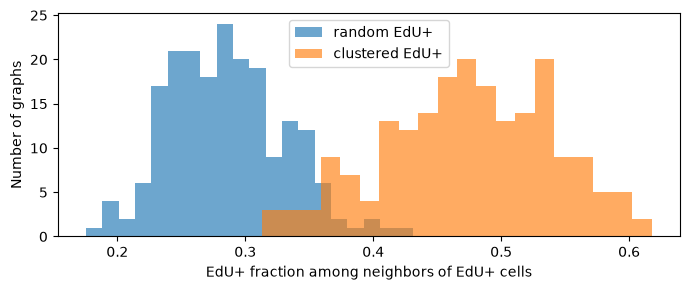

In [5]:
def graph_summaries(graph: Data):
    pos = graph.pos
    distance = torch.cdist(pos, pos)
    distance.fill_diagonal_(float('inf'))
    e = graph.x[:, 0]
    global_features = np.array([
        graph.num_nodes, e.mean().item(), graph.x[:, 1].mean().item(),
        graph.x[:, 2].mean().item(), torch.linalg.vector_norm(pos[:, :2], dim=1).mean().item(),
        distance.min(dim=1).values.mean().item(),
    ])
    source, target = graph.edge_index
    positive_neighbor_fraction = (e[source] * e[target]).sum() / e[source].sum()
    return global_features, float(positive_neighbor_fraction)

flat = [graph for pair in pairs for graph in pair]
summaries = [graph_summaries(g) for g in flat]
global_x = np.stack([v[0] for v in summaries])
spatial_x = np.column_stack((global_x, [v[1] for v in summaries]))
y = np.array([int(g.y.item()) for g in flat])
def graph_indices(ids):
    return np.array([j for pair_id in ids for j in (2*pair_id, 2*pair_id+1)])

train_i, val_i, test_i = (graph_indices(ids) for ids in (train_ids, val_ids, test_ids))
models = {}
for name, values in [('global summary', global_x), ('spatial summary', spatial_x)]:
    baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
    baseline.fit(values[train_i], y[train_i])
    models[name] = (baseline, values)
    pred = baseline.predict(values[val_i])
    print(f'{name}: validation accuracy = {accuracy_score(y[val_i], pred):.3f}')

assert np.allclose(global_x[::2], global_x[1::2])
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(spatial_x[0::2, -1], bins=20, alpha=0.65, label='random EdU+')
ax.hist(spatial_x[1::2, -1], bins=20, alpha=0.65, label='clustered EdU+')
ax.set(xlabel='EdU+ fraction among neighbors of EdU+ cells', ylabel='Number of graphs')
ax.legend()
plt.tight_layout()


## 5. A graph neural network using PyTorch Geometric

For node $i$, `SAGEConv` learns from its own features and the **mean of neighboring features**. In simplified form, $h_i^{(1)}=\mathrm{ReLU}(W_{\rm self}x_i + W_{\rm neigh}\,\operatorname{mean}_{j\in N(i)}x_j+b)$. Another layer can combine information over a larger neighborhood. We pool the resulting cell vectors by their mean and maximum to make one prediction per lobe.

The model sees only node features and nearest-neighbor edges. It does not receive the label, pair ID, positions, radial distance, or the hand-engineered edge statistic. Volume and Dpn intensity are nuisance features, not simulated treatment effects.


In [6]:
class LobeSAGE(torch.nn.Module):
    def __init__(self, hidden: int = 32):
        super().__init__()
        self.conv1 = SAGEConv(3, hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.classifier = torch.nn.Linear(2 * hidden, 1)

    def forward(self, batch):
        h = F.relu(self.conv1(batch.x, batch.edge_index))
        h = F.relu(self.conv2(h, batch.edge_index))
        pooled = torch.cat((global_mean_pool(h, batch.batch),
                            global_max_pool(h, batch.batch)), dim=1)
        return self.classifier(pooled).view(-1)

print(LobeSAGE())


LobeSAGE(
  (conv1): SAGEConv(3, 32, aggr=mean)
  (conv2): SAGEConv(32, 32, aggr=mean)
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)


## 6. Fit three initializations, using validation loss for early stopping

The training split fits the weights; validation chooses the epoch. Three random starts reveal whether the result is sensitive to initialization. The **test set is not used to choose an epoch, seed, threshold, architecture, or simulation strength**. This remains a small synthetic exercise, not a power analysis for a real animal study.


/sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/lib64/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed=17 best epoch=32 validation accuracy=0.963


/sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/lib64/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed=18 best epoch=32 validation accuracy=0.963


/sfs/gpfs/tardis/home/tqv9uu/vistiqlab/vistiq/.venv/lib64/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed=19 best epoch=29 validation accuracy=0.963


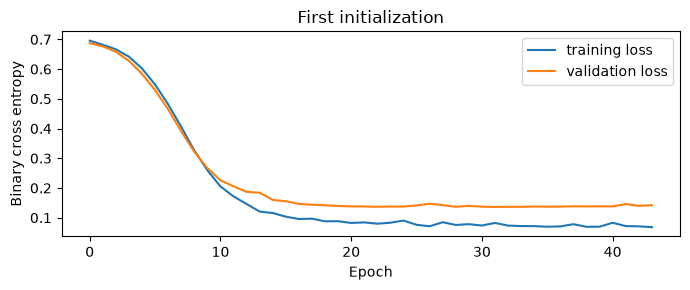

In [7]:
@torch.no_grad()
def predict_model(model, loader):
    model.eval()
    logits, labels_out = [], []
    for batch in loader:
        batch = batch.to(device)
        logits.append(model(batch).cpu())
        labels_out.append(batch.y.cpu())
    return torch.cat(logits), torch.cat(labels_out)

def fit_model(seed, max_epochs=80, patience=12):
    torch.manual_seed(seed)
    model = LobeSAGE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-4)
    history = {'train': [], 'validation': []}
    best_loss, best_epoch, best_weights = float('inf'), 0, None

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = F.binary_cross_entropy_with_logits(model(batch), batch.y.float())
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch.num_graphs

        scores, targets = predict_model(model, val_loader)
        val_loss = F.binary_cross_entropy_with_logits(scores, targets.float()).item()
        history['train'].append(total_loss / len(train_graphs))
        history['validation'].append(val_loss)
        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch = val_loss, epoch
            best_weights = copy.deepcopy(model.state_dict())
        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_weights)
    scores, targets = predict_model(model, val_loader)
    val_accuracy = accuracy_score(targets.numpy(), (scores >= 0).long().numpy())
    return model, history, best_epoch, val_accuracy

trained = []
for run_seed in (SEED, SEED + 1, SEED + 2):
    fitted = fit_model(run_seed)
    trained.append(fitted)
    print(f'seed={run_seed} best epoch={fitted[2]} validation accuracy={fitted[3]:.3f}')

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(trained[0][1]['train'], label='training loss')
ax.plot(trained[0][1]['validation'], label='validation loss')
ax.set(xlabel='Epoch', ylabel='Binary cross entropy', title='First initialization')
ax.legend()
plt.tight_layout()


## 7. Evaluate the untouched test pairs

Report accuracy and ROC AUC for the two baselines and each GNN initialization. Scores around 0.5 mean chance on this balanced paired task. Because graphs come in matched pairs, also report how often the positive graph receives a higher score than its control partner (ties count as half). A bootstrap **resamples whole test pairs** to summarize uncertainty in accuracy; it does **not** account for simulation misspecification or model selection outside this notebook.


In [8]:
def paired_bootstrap_interval(correct, repetitions=2000):
    by_pair = correct.reshape(-1, 2).mean(axis=1)
    bootstrap_rng = np.random.default_rng(SEED + 555)
    samples = bootstrap_rng.choice(by_pair, size=(repetitions, len(by_pair)),
                                   replace=True).mean(axis=1)
    return np.quantile(samples, [0.025, 0.975])

assert np.array_equal(y[test_i], np.tile([0, 1], len(test_ids)))
def report(name, probabilities):
    truth = y[test_i]
    pred = (probabilities >= 0.5).astype(int)
    correct = (pred == truth)
    lo, hi = paired_bootstrap_interval(correct)
    gap = probabilities[1::2] - probabilities[0::2]
    pair_ranking = np.mean((gap > 1e-12) + 0.5 * (np.abs(gap) <= 1e-12))
    print(f'{name}: accuracy={correct.mean():.3f} '
          f'(95% paired bootstrap [{lo:.3f}, {hi:.3f}]), '
          f'AUC={roc_auc_score(truth, probabilities):.3f}, '
          f'pair ranking={pair_ranking:.3f}')
    return pred

for name, (baseline, values) in models.items():
    report(name, baseline.predict_proba(values[test_i])[:, 1])

test_probabilities = []
for run, (model, _, _, _) in enumerate(trained, 1):
    scores, targets = predict_model(model, test_loader)
    assert np.array_equal(targets.numpy(), y[test_i])
    probabilities = scores.sigmoid().numpy()
    test_probabilities.append(probabilities)
    predictions = report(f'GraphSAGE seed {run}', probabilities)
    if run == 1:
        print('First GNN confusion matrix [control, clustered] rows/columns:')
        print(confusion_matrix(targets.numpy(), predictions, labels=[0, 1]))


global summary: accuracy=0.500 (95% paired bootstrap [0.500, 0.500]), AUC=0.500, pair ranking=0.500
spatial summary: accuracy=0.900 (95% paired bootstrap [0.825, 0.963]), AUC=0.972, pair ranking=0.950
GraphSAGE seed 1: accuracy=1.000 (95% paired bootstrap [1.000, 1.000]), AUC=1.000, pair ranking=1.000
First GNN confusion matrix [control, clustered] rows/columns:
[[40  0]
 [ 0 40]]
GraphSAGE seed 2: accuracy=1.000 (95% paired bootstrap [1.000, 1.000]), AUC=1.000, pair ranking=1.000
GraphSAGE seed 3: accuracy=0.988 (95% paired bootstrap [0.963, 1.000]), AUC=1.000, pair ranking=1.000


## 8. Feature-shuffling control

Shuffle only the EdU-positive indicators **within each held-out graph**, keeping its number of positive cells, positions, edges, and other features fixed. This destroys the class-specific spatial pattern. An already trained GNN that uses neighbor organization should generally lose discrimination under this intervention. The transformed examples are outside their original class-generating process, so their accuracy is a diagnostic rather than a normal test score.


In [9]:
shuffle_rng = np.random.default_rng(SEED + 1000)
shuffled_test = []
for graph in test_graphs:
    changed = graph.clone()
    permutation = torch.as_tensor(shuffle_rng.permutation(graph.num_nodes), dtype=torch.long)
    changed.x[:, 0] = graph.x[permutation, 0]
    shuffled_test.append(changed)
shuffled_scores, shuffled_labels = predict_model(trained[0][0], DataLoader(shuffled_test, batch_size=64))
shuffled_probs = shuffled_scores.sigmoid().numpy()
print('First GNN AUC after EdU shuffling:',
      round(roc_auc_score(shuffled_labels.numpy(), shuffled_probs), 3))
print('First GNN pair ranking after shuffling:',
      round(np.mean(shuffled_probs[1::2] > shuffled_probs[0::2]), 3))


First GNN AUC after EdU shuffling: 0.488
First GNN pair ranking after shuffling: 0.4


## Interpretation and next experiment

- **Global-summary baseline ≈ 0.5:** confirms the matched design blocks its shortcut. **Spatial baseline above 0.5:** confirms that simple local EdU association can solve some of the simulated problem. If the GNN matches or trails that baseline, this proof of concept gives no reason to prefer it for this task.
- **GNN above 0.5 across seeds, but shuffled control ≈ 0.5:** is consistent with learning the synthetic spatial relationship. Scores will vary. Results may remain high if the simulated clustering is still too strong, or remain near chance if it is too weak for this architecture.
- All effects and labels were generated by us. No result here estimates a biological effect, measures segmentation IoU/IoS, or predicts a real experimental condition.
- For a real study, derive graph nodes from segmented cells and measured features, define EdU status from channels with quality control, choose edges using physical pixel sizes and biologically meaningful neighborhoods, obtain independent outcome labels, and split **by animal and acquisition batch**. Compare against spatial statistics and simpler models before proposing a GNN.
